<a href="https://colab.research.google.com/github/jpnoug/spectropy/blob/main/nova_V488Sge(avec%20suivi%20temporel).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/jpnoug/spectropy/blob/main/nova_V488Sge.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Nova V488 Sge (Nova Sagittae 2026) — spectre Alpy 600

**Contexte** : PNV J19450648+1822422, découverte le 2026-08-25 (NMW-TexasTech), pic vers V ≈ 6–7, profils P Cygni en Hα/Hβ à ~1500 km/s le soir de la découverte, déclin rapide (V ≈ 9.5 au 1er septembre → nova *rapide*). Distance Gaia du progéniteur ≈ 6.3 kpc ; le progéniteur est un candidat binaire à éclipses (P ≈ 9.9 j, donc probablement un compagnon évolué).

Contenu du notebook :
1. chargement du FITS 1D, âge de la nova au moment de l'observation ;
2. **vue sobre** (linéaire + log, la vue log est indispensable en phase nébulaire : Hα écrase tout) ;
3. **vue colorisée** λ→RGB sous la courbe (même méthode que 2026rdg) avec **raies annotées** et étiquettes étagées ;
4. **pseudo-continuum global** par points de continu (à valider visuellement) ;
5. **largeurs de raies** (FWHM, FW10 %, déconvolution instrumentale, ajustement gaussien, superposition en vitesse) ;
6. **diagnostic de phase** : flux des raies clés relatifs à Hβ et classification indicative de type Tololo (P / A / N / C) ;
7. **suivi multi-époques** avec la base ARAS (F. Teyssier) : évolution des vitesses, des rapports de raies et de la phase, séquence spectrale, profils Hα haute résolution, recoupement avec les spectres voisins.

In [ ]:
# --- Chargement (Colab) ---
try:
    from google.colab import files
    uploaded = files.upload()          # sélectionner le .fit
    FILE = list(uploaded.keys())[0]
except ImportError:                    # exécution locale
    FILE = '_v488_sge_20260926_890.fits'

import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.time import Time

# --- Paramètres à ajuster ---
OBJECT   = 'Nova V488 Sge'
SETUP    = 'JPN — Newton 200 / Alpy 600 / Atik 414EX — 25×60 s'
R_INST   = 523                         # SPE_RPOW du header ISIS
T0_ISO   = '2026-08-25T10:39:00'       # découverte (2026-08-25.444 UT) ; remplacer par la date du max si tu préfères
XLIM     = (3900, 7450)

Saving _v488_sge_20260926_890.fits to _v488_sge_20260926_890.fits


In [ ]:
def load_spectrum(path):
    """(wavelength [Å], flux, meta) depuis un FITS 1D linéaire (ISIS)."""
    with fits.open(path) as hdul:
        h = hdul[0].header
        flux = hdul[0].data.astype(float).squeeze()
        n = h['NAXIS1']
        crpix = h.get('CRPIX1', 1)
        wl = h['CRVAL1'] + (np.arange(n) + 1 - crpix) * h['CDELT1']
        meta = {'date': h.get('DATE-OBS', None), 'exptime': h.get('EXPTIME', np.nan),
                'header': h.copy()}
    return wl, flux, meta

wl, flux, meta = load_spectrum(FILE)
good = np.isfinite(flux)
wl, flux = wl[good], flux[good]

hdr = meta['header']
if 'SPE_RPOW' in hdr:                          # R mesuré par ISIS
    R_INST = float(hdr['SPE_RPOW'])
if 'BSS_INST' in hdr:
    SETUP = f"{hdr.get('OBSERVER', '')} — {hdr['BSS_INST']} — {hdr.get('EXPTIME2', '')}".replace('?m', 'µm')

t_obs = Time(meta['date']) if meta['date'] else None
t0    = Time(T0_ISO)
AGE   = (t_obs - t0).jd if t_obs is not None else np.nan
DATE_LABEL = t_obs.isot[:16].replace('T', ' ') + ' UT' if t_obs is not None else '?'

print(f"{wl[0]:.1f}–{wl[-1]:.1f} Å, {len(wl)} pts, dispersion {np.median(np.diff(wl)):.2f} Å/pix")
print(f"DATE-OBS = {meta['date']}   EXPTIME = {meta['exptime']} s")
print(f"Âge depuis T0 : t = {AGE:.2f} j   |   R = {R_INST:.0f}")
if hdr.get('Q_CAL', 1) == 0 or str(hdr.get('BSS_TELL', '')) == 'None':
    print("Note : Q_CAL=0 / pas de correction tellurique → rapports de flux bleu/rouge à prendre avec prudence.")

# normalisation pour l'affichage : pic de Hα = 1 (le continuum est faible chez une nova évoluée)
m_ha = (wl > 6500) & (wl < 6630)
FNORM = np.nanmax(flux[m_ha]) if m_ha.any() else np.nanmax(flux)
fn = flux / FNORM

3575.5–7370.0 Å, 7590 pts, dispersion 0.50 Å/pix
DATE-OBS = 2026-09-26T21:21:53   EXPTIME = 1553 s
Âge depuis T0 : t = 32.45 j   |   R = 505
Note : Q_CAL=0 / pas de correction tellurique → rapports de flux bleu/rouge à prendre avec prudence.


## 1. Vue sobre
Deux panneaux : échelle linéaire (Hα = 1) et échelle logarithmique, qui fait ressortir les raies faibles (He II, [N II] 5755, raies coronales…).

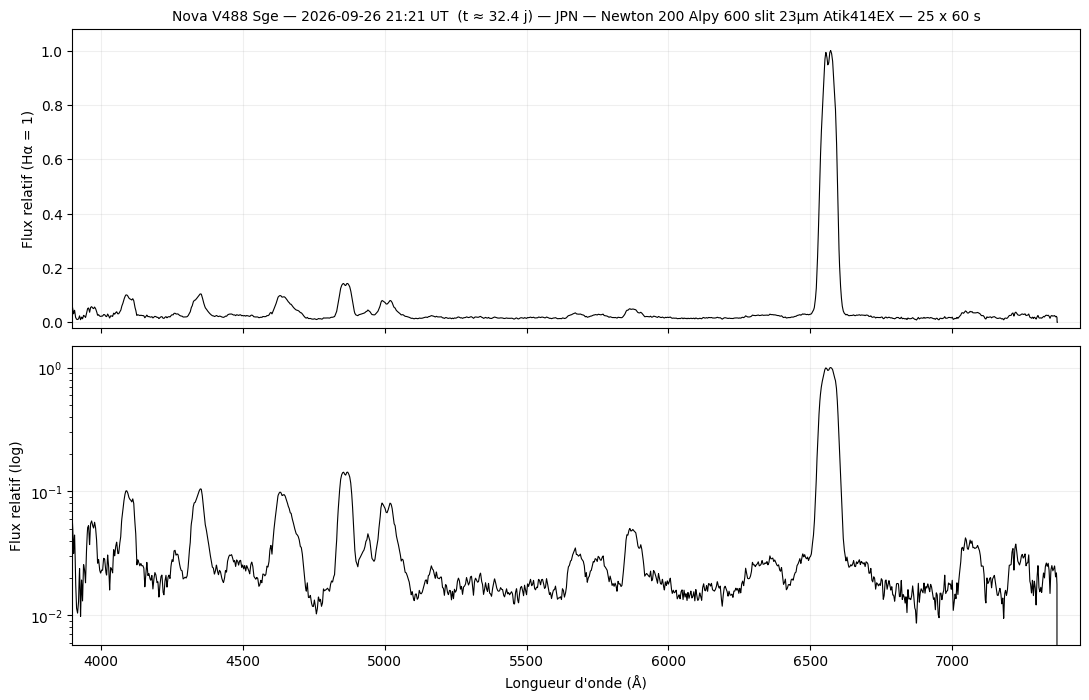

In [ ]:
def plot_sober(wl, fn, xlim=XLIM, annotate=False):
    m = (wl >= xlim[0]) & (wl <= xlim[1])
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(13, 8), sharex=True,
                                 gridspec_kw={'hspace': 0.06})
    for ax in (a1, a2):
        ax.plot(wl[m], fn[m], color='k', lw=0.8)
        ax.grid(alpha=0.2)
    a1.set_ylim(-0.02, 1.08)
    a1.set_ylabel('Flux relatif (Hα = 1)')
    pos = fn[m][fn[m] > 0]
    a2.set_yscale('log')
    a2.set_ylim(np.percentile(pos, 1) * 0.5, 1.5)
    a2.set_ylabel('Flux relatif (log)')
    a2.set_xlabel("Longueur d'onde (Å)")
    a2.set_xlim(xlim)
    a1.set_title(f'{OBJECT} — {DATE_LABEL}  (t ≈ {AGE:.1f} j) — {SETUP}', fontsize=10)
    if annotate:
        annotate_lines(a2, xlim, log=True)
    plt.show()

# (annotate_lines est définie plus bas ; relancer avec annotate=True après la section 2)
plot_sober(wl, fn)

## 2. Liste de raies et annotation

Liste adaptée à une nova rapide **~1 mois** après l'éruption : Balmer, He I, He II / Bowen, raies interdites nébulaires et aurorales, O I, restes de Fe II, et raies coronales possibles. Mettre `show=False` (ou commenter) ce qui n'est pas vu.

Les étiquettes sont automatiquement réparties sur 3 niveaux pour éviter les chevauchements.

In [ ]:
# (label, λ Å, catégorie, show)
LINES = [
    ("[Ne III] 3869",  3868.8, 'neb',    True),
    ("Hε+[Ne III]",    3969.0, 'balmer', True),
    ("Hδ",             4101.7, 'balmer', True),
    ("Hγ",             4340.5, 'balmer', True),
    ("[O III] 4363",   4363.2, 'aur',    True),
    ("He I 4471",      4471.5, 'hei',    True),
    ("N III 4640",     4640.0, 'n',      True),   # fluorescence de Bowen
    ("He II 4686",     4685.7, 'heii',   True),
    ("Hβ",             4861.3, 'balmer', True),
    ("[O III] 4959",   4958.9, 'neb',    True),
    ("[O III] 5007",   5006.8, 'neb',    True),
    ("He I 4922",      4921.9, 'hei',    True),
    ("Fe II 5169",     5169.0, 'fe',     False),
    ("N II 5679",      5679.6, 'n',      True),   # marqueur des novae He/N  # dominant au début, en principe disparu
    ("He II 5411",     5411.5, 'heii',   False),  # non vue le 2026-09-26
    ("[N II] 5755",    5754.6, 'aur',    True),
    ("He I 5876",      5875.6, 'hei',    True),
    ("[Fe VII] 6087",  6086.9, 'cor',    False),  # non vue le 2026-09-26
    ("[O I] 6300",     6300.3, 'neb',    True),
    ("[O I] 6364",     6363.8, 'neb',    True),
    ("[Fe X] 6375",    6374.5, 'cor',    True),
    ("[N II] 6548",    6548.0, 'neb',    False),
    ("Hα",             6562.8, 'balmer', True),
    ("[N II] 6583",    6583.5, 'neb',    True),
    ("He I 6678",      6678.2, 'hei',    True),
    ("He I 7065",      7065.2, 'hei',    True),
    ("[Ar III] 7136",  7135.8, 'neb',    True),
    ("[O II] 7325",    7325.0, 'neb',    True),
    ("O I 7773",       7773.4, 'o',      True),
]

CAT_COLORS = {'balmer': 'black', 'hei': 'tab:purple', 'heii': 'tab:red',
              'n': 'tab:green', 'neb': 'tab:blue', 'aur': 'tab:cyan',
              'cor': 'tab:orange', 'fe': 'tab:brown', 'o': 'tab:olive'}

BANDS = [  # telluriques
    ("O$_2$ B", (6867.0, 6884.0)),
    ("H$_2$O",  (7160.0, 7340.0)),
    ("O$_2$ A", (7594.0, 7685.0)),
]

def annotate_lines(ax, xlim, ymax=None, log=False, min_sep=42.0, nlev=3):
    """Traits pointillés + étiquettes verticales étagées pour éviter les chevauchements."""
    y0, y1 = ax.get_ylim()
    lv = []
    for k in range(nlev):
        if log:
            lv.append(10 ** (np.log10(y1) - (0.02 + 0.15 * k) * (np.log10(y1) - np.log10(y0))))
        else:
            lv.append(y1 - (0.02 + 0.15 * k) * (y1 - y0))
    last = [-1e9] * nlev
    for name, lam, cat, show in sorted(LINES, key=lambda t: t[1]):
        if not show or not (xlim[0] <= lam <= xlim[1]):
            continue
        k = next((i for i in range(nlev) if lam - last[i] >= min_sep), int(np.argmin(last)))
        last[k] = lam
        col = CAT_COLORS.get(cat, 'gray')
        ax.plot([lam, lam], [y0, lv[k]], color=col, ls=':', lw=0.6, alpha=0.6, zorder=3)
        ax.text(lam, lv[k], name, rotation=90, ha='center', va='top',
                fontsize=7.5, color=col, zorder=4,
                bbox=dict(fc='white', ec='none', alpha=0.7, pad=0.3))
    for name, (a, b) in BANDS:
        if b >= xlim[0] and a <= xlim[1]:
            ax.axvspan(a, b, color='tab:blue', alpha=0.10, zorder=2)

## 3. Spectre colorisé (λ→RGB sous la courbe) + annotations
Même fonction couleur que pour 2026rdg (approximation CIE de Dan Bruton), rendu par un seul `imshow` clippé sous la courbe. L'axe Y est étendu à ~1.6 × le pic pour loger les étiquettes au-dessus du spectre.

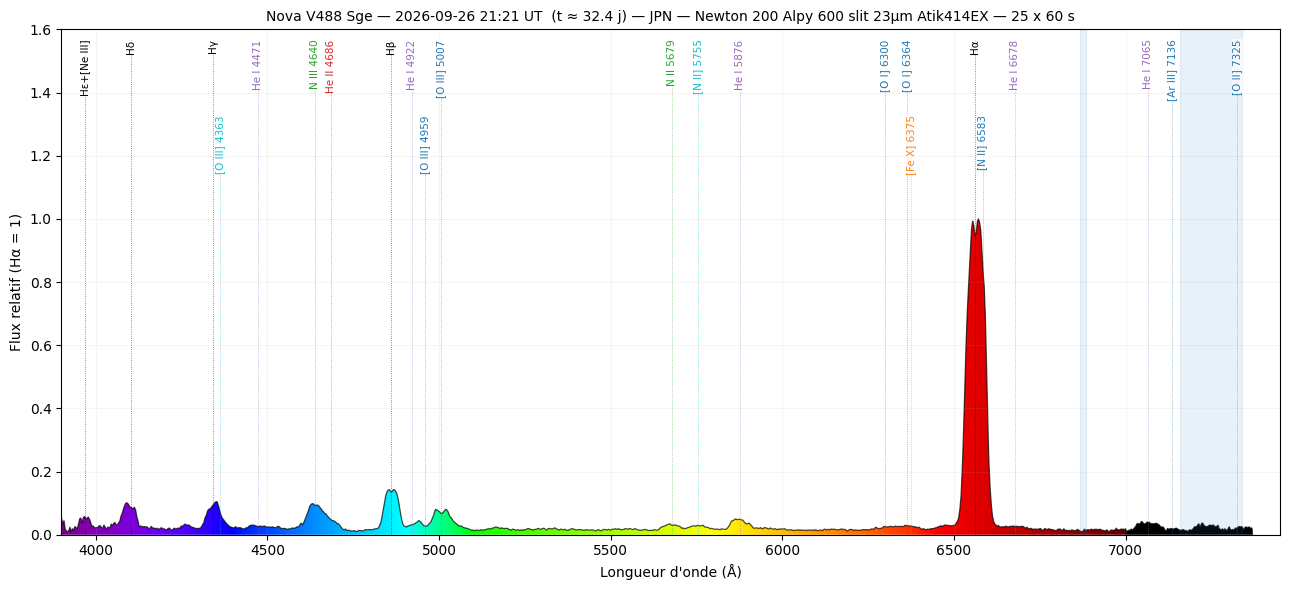

In [ ]:
def wavelength_to_rgb(wl_ang, gamma=0.8):
    wl = wl_ang / 10.0
    if wl < 380 or wl > 700:
        return (0.0, 0.0, 0.0)
    if wl < 440:   r, g, b = -(wl - 440) / 60, 0.0, 1.0
    elif wl < 490: r, g, b = 0.0, (wl - 440) / 50, 1.0
    elif wl < 510: r, g, b = 0.0, 1.0, -(wl - 510) / 20
    elif wl < 580: r, g, b = (wl - 510) / 70, 1.0, 0.0
    elif wl < 645: r, g, b = 1.0, -(wl - 645) / 65, 0.0
    else:          r, g, b = 1.0, 0.0, 0.0
    if wl < 420:   f = 0.3 + 0.7 * (wl - 380) / 40
    elif wl > 645: f = 0.3 + 0.7 * (700 - wl) / 55
    else:          f = 1.0
    return ((r * f) ** gamma, (g * f) ** gamma, (b * f) ** gamma)

_wl_grid  = np.arange(3700, 7801, 2.0)
_rgb_grid = np.array([wavelength_to_rgb(w) for w in _wl_grid])
def rgb_at(w):
    return _rgb_grid[np.clip(np.searchsorted(_wl_grid, w), 0, len(_wl_grid) - 1)]

from matplotlib.patches import Polygon

def plot_colored(wl, fn, xlim=XLIM, annotate=True, headroom=1.6):
    m = (wl >= xlim[0]) & (wl <= xlim[1])
    w, y = wl[m], fn[m]
    ybase = min(0.0, np.nanmin(y))
    YMAX = np.nanmax(y) * headroom
    fig, ax = plt.subplots(figsize=(13, 6))
    im = ax.imshow(rgb_at(w)[np.newaxis, :, :], extent=[w[0], w[-1], ybase, YMAX],
                   aspect='auto', origin='lower', zorder=0)
    verts = np.vstack([np.column_stack([w, y]), [[w[-1], ybase], [w[0], ybase]]])
    im.set_clip_path(Polygon(verts, closed=True, transform=ax.transData))
    ax.plot(w, y, color='k', lw=0.9, alpha=0.7, zorder=1)
    ax.set_xlim(xlim); ax.set_ylim(0, YMAX)
    if annotate:
        annotate_lines(ax, xlim)
    ax.set_xlabel("Longueur d'onde (Å)")
    ax.set_ylabel('Flux relatif (Hα = 1)')
    ax.set_title(f'{OBJECT} — {DATE_LABEL}  (t ≈ {AGE:.1f} j) — {SETUP}', fontsize=10)
    ax.grid(alpha=0.12)
    plt.tight_layout(); plt.show()

plot_colored(wl, fn)

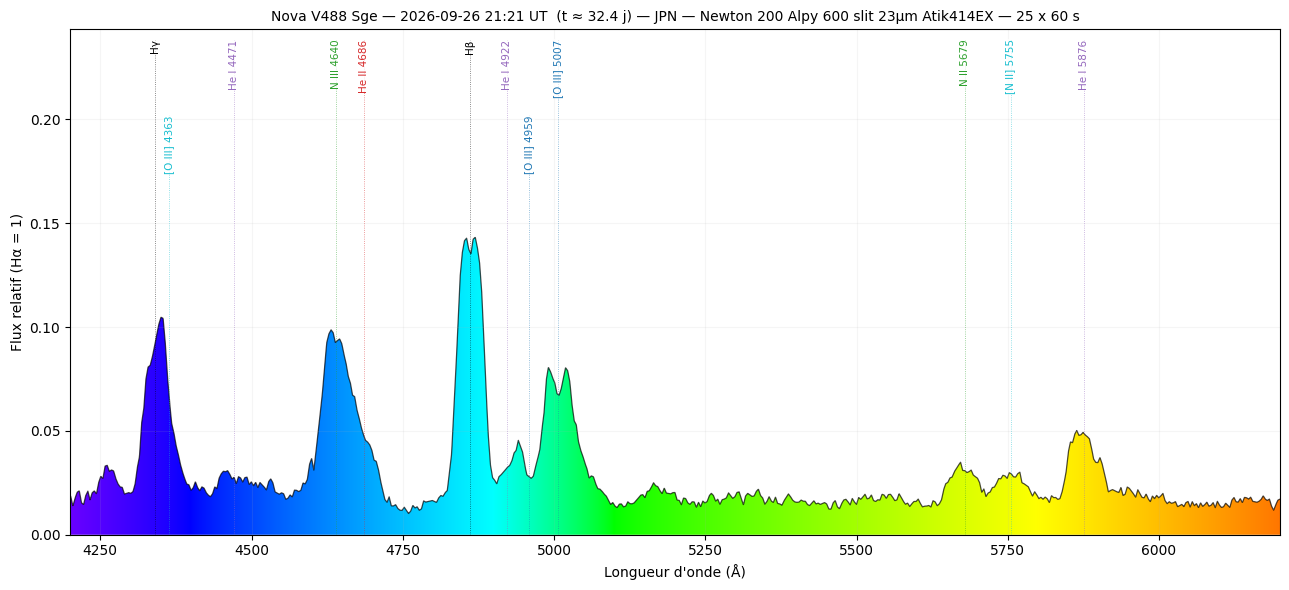

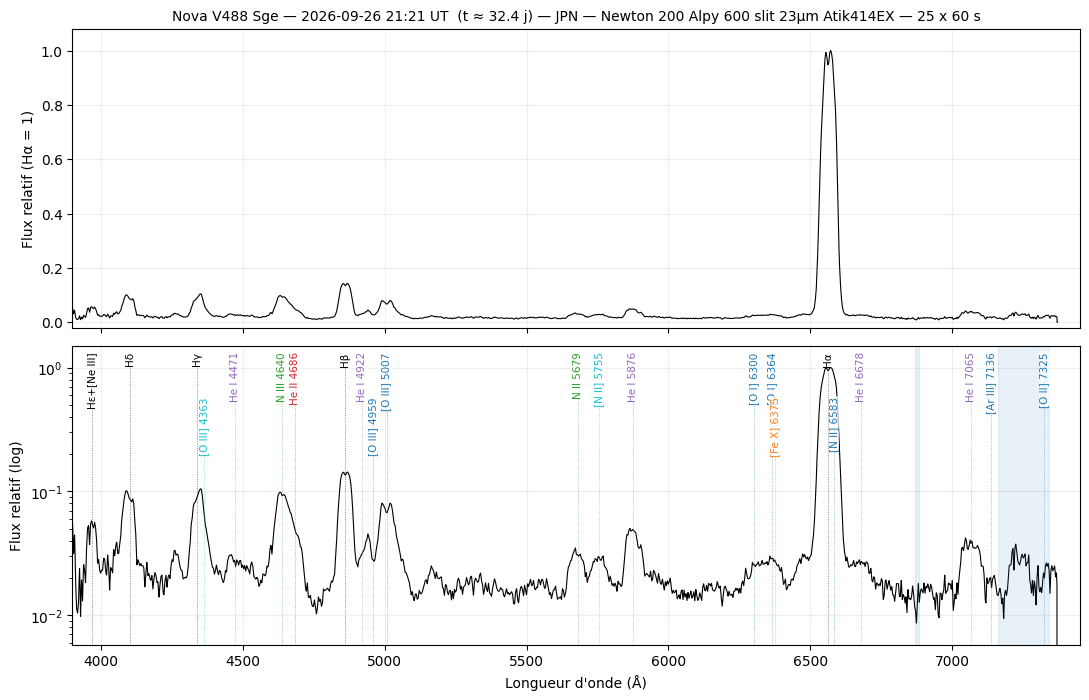

In [ ]:
# Vue colorisée zoomée sur le bleu-vert (raies faibles) : on "tronque" Hα
plot_colored(wl, fn, xlim=(4200, 6200), headroom=1.7)
# Vue sobre annotée (log)
plot_sober(wl, fn, annotate=True)

## 4. Pseudo-continuum global
Chez une nova à ce stade le continuum est faible et les ailes des raies se recouvrent : on le définit par une série de **points de continu** (médiane ± `HW` Å), interpolés par PCHIP (pas d'oscillations). **À vérifier sur la figure** et à ajuster (ajouter/retirer des points) avant de mesurer quoi que ce soit.

Bruit par pixel estimé à la manière de DER_SNR (Stoehr et al. 2008).

Bins de 11 pix (5.5 Å) : bruit ≈ 2.18e-03 (Hα = 1)
S/N au pic de Hα ≈ 459   |   S/N sur le continuum ≈ 8 (par 5.5 Å)


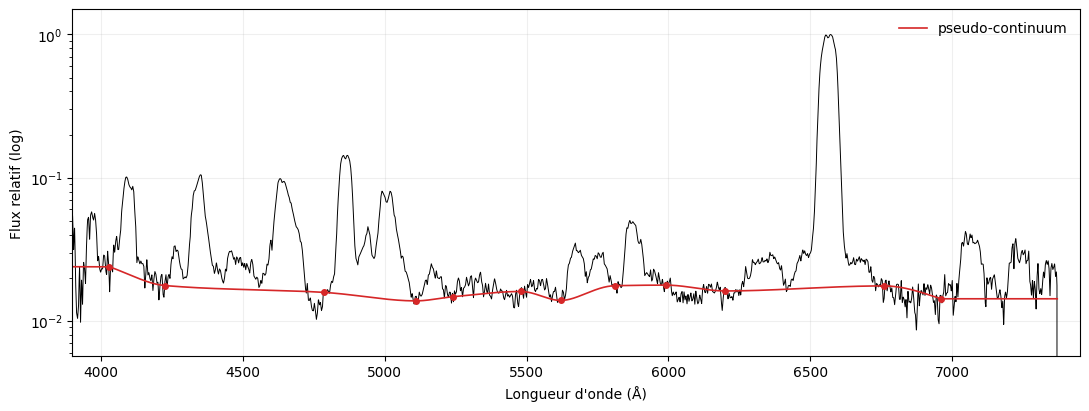

In [ ]:
from scipy.interpolate import PchipInterpolator

CONT_POINTS = [4030, 4225, 4785, 5110, 5240, 5480, 5620, 5810, 5990, 6200,
               6760, 6960]
HW = 8.0

def build_continuum(wl, f, pts=CONT_POINTS, hw=HW):
    xs, ys = [], []
    for p in pts:
        mm = (wl >= p - hw) & (wl <= p + hw)
        if mm.sum() >= 3:
            xs.append(p); ys.append(np.median(f[mm]))
    xs, ys = np.array(xs), np.array(ys)
    interp = PchipInterpolator(xs, ys, extrapolate=False)
    c = interp(wl)
    c[wl < xs[0]] = ys[0]; c[wl > xs[-1]] = ys[-1]
    return c, xs, ys

def der_snr_noise(f):
    f = f[np.isfinite(f)]
    return 1.482602 / np.sqrt(6.0) * np.median(np.abs(2.0 * f[2:-2] - f[:-4] - f[4:]))

# Le spectre ISIS est ré-échantillonné (0.5 Å/pix ≪ élément de résolution) : le bruit est
# corrélé entre pixels voisins et DER_SNR pixel à pixel le sous-estime fortement.
# → DER_SNR sur des bins d'un demi-élément de résolution, puis bruit "blanc équivalent"
#   par pixel (SIGMA) pour la propagation d'erreur.
dpix = np.median(np.diff(wl))
NBIN = max(1, int(round(5500 / R_INST / 2 / dpix)))
nb_ = len(fn) // NBIN
fbin = fn[:nb_ * NBIN].reshape(nb_, NBIN).mean(axis=1)
SIG_BIN = der_snr_noise(fbin)
SIGMA = SIG_BIN * np.sqrt(NBIN)

cont, cx, cy = build_continuum(wl, fn)
print(f"Bins de {NBIN} pix ({NBIN*dpix:.1f} Å) : bruit ≈ {SIG_BIN:.2e} (Hα = 1)")
print(f"S/N au pic de Hα ≈ {1/SIG_BIN:.0f}   |   S/N sur le continuum ≈ {np.median(cont)/SIG_BIN:.0f} (par {NBIN*dpix:.1f} Å)")

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(wl, fn, 'k', lw=0.7)
ax.plot(wl, cont, color='tab:red', lw=1.2, label='pseudo-continuum')
ax.plot(cx, cy, 'o', color='tab:red', ms=4)
ax.set_yscale('log'); ax.set_xlim(XLIM)
ax.set_ylim(np.percentile(fn[fn > 0], 1) * 0.5, 1.5)
ax.legend(frameon=False); ax.grid(alpha=0.2)
ax.set_xlabel("Longueur d'onde (Å)"); ax.set_ylabel('Flux relatif (log)')
plt.show()

## 5. Largeurs de raies

Pour chaque raie : intégration de (flux − continuum) dans une fenêtre, puis
- **FWHM** et **FW10 %** mesurées directement (croisements les plus externes, donc robustes aux profils en « cornes » / plateau), converties en km/s ;
- **déconvolution instrumentale** en quadrature : FWHM_inst = c / R ≈ 600 km/s à R = 500 — c'est non négligeable ;
- ajustement **gaussien** (comparaison seulement : les profils de nova sont rarement gaussiens) ;
- **centroïde** en vitesse (non corrigé héliocentrique, ±30 km/s).

FW10 % / 2 est une bonne approche de la vitesse maximale des éjecta (≈ HWZI). ⚠ Hα contient [N II] 6548/6583, qui élargissent l'aile rouge au fur et à mesure que la nova devient nébulaire.

In [ ]:
from scipy.optimize import curve_fit
C_KMS = 299792.458

# (label, λ0, (λmin, λmax) d'intégration)
WIDTH_LINES = [
    ("Hα (+[N II])",       6562.8, (6460, 6660)),
    ("Hβ",                 4861.3, (4780, 4925)),
    ("Hγ (+[O III] 4363)", 4340.5, (4275, 4410)),
    ("He I 5876",          5875.6, (5815, 5945)),
]

def gauss(x, a, mu, s):
    return a * np.exp(-0.5 * ((x - mu) / s) ** 2)

def _cross(x, y, lev, ipk):
    """Croisements du niveau lev en partant du pic vers l'extérieur, côté par côté.
    NaN d'un côté si le niveau n'est pas atteint dans la fenêtre (blend)."""
    L = np.where(y[:ipk] < lev)[0]
    Rr = np.where(y[ipk:] < lev)[0]
    xl = xr = np.nan
    if len(L):
        i = L[-1]; xl = np.interp(lev, [y[i], y[i + 1]], [x[i], x[i + 1]])
    if len(Rr):
        j = ipk + Rr[0]; xr = np.interp(lev, [y[j], y[j - 1]], [x[j], x[j - 1]])
    return xl, xr

def measure_line(label, lam0, win, wl=wl, f=fn, c=cont, R=R_INST):
    m = (wl >= win[0]) & (wl <= win[1])
    x, y = wl[m], f[m] - c[m]
    dl = np.gradient(x)
    F = np.sum(y * dl)
    eF = SIGMA * np.sqrt(m.sum()) * np.median(dl)
    ipk = np.argmax(y); pk = y[ipk]
    xl, xr = _cross(x, y, 0.5 * pk, ipk)
    x10l, x10r = _cross(x, y, 0.1 * pk, ipk)
    fwhm = (xr - xl) / lam0 * C_KMS
    fw10 = (x10r - x10l) / lam0 * C_KMS
    hw10b = (lam0 - x10l) / lam0 * C_KMS      # demi-largeur à 10 %, côté bleu
    hw10r = (x10r - lam0) / lam0 * C_KMS      # côté rouge
    inst = C_KMS / R
    fwhm_dec = np.sqrt(fwhm**2 - inst**2) if fwhm > inst else np.nan
    cen = np.sum(x * y * dl) / F
    try:
        p, _ = curve_fit(gauss, x, y, p0=[pk, lam0, 15.0])
        fwhm_g = 2.3548 * abs(p[2]) / lam0 * C_KMS
    except Exception:
        p, fwhm_g = None, np.nan
    return dict(label=label, lam0=lam0, x=x, y=y, flux=F, eflux=eF, peak=pk,
                xl=xl, xr=xr, fwhm=fwhm, hw10b=hw10b, hw10r=hw10r, fwhm_dec=fwhm_dec, fw10=fw10,
                v_cen=(cen - lam0) / lam0 * C_KMS, fwhm_g=fwhm_g, pfit=p)

res = [measure_line(*L) for L in WIDTH_LINES if WIDTH_LINES and wl[0] < L[2][0] and wl[-1] > L[2][1]]

print(f"FWHM instrumentale ≈ {C_KMS/R_INST:.0f} km/s (R = {R_INST})\n")
def _f(v, w):
    return f"{v:{w}.0f}" if np.isfinite(v) else f"{'blend':>{w}s}"
print(f"{'raie':19s} {'FWHM obs':>9s} {'FWHM déconv':>12s} {'FWHM gauss':>11s} {'HW10 bleu':>10s} {'HW10 rouge':>11s} {'v_cen':>7s}   [km/s]")
for r in res:
    print(f"{r['label']:19s} {_f(r['fwhm'],9)} {_f(r['fwhm_dec'],12)} {_f(r['fwhm_g'],11)} "
          f"{_f(r['hw10b'],10)} {_f(r['hw10r'],11)} {r['v_cen']:+7.0f}")
print("\nHW10 ≈ HWZI : vitesse maximale projetée des éjecta. 'blend' = niveau 10 % non atteint (raie voisine).")

FWHM instrumentale ≈ 594 km/s (R = 505.0)

raie                 FWHM obs  FWHM déconv  FWHM gauss  HW10 bleu  HW10 rouge   v_cen   [km/s]
Hα (+[N II])             2869         2807        2530       1940        2046     +47
Hβ                       2990         2930        2761       2149        2276    +194
Hγ (+[O III] 4363)       3012         2953        3203       2224        3515    +383
He I 5876                2971         2911        2573       1815        2066    +153

HW10 ≈ HWZI : vitesse maximale projetée des éjecta. 'blend' = niveau 10 % non atteint (raie voisine).


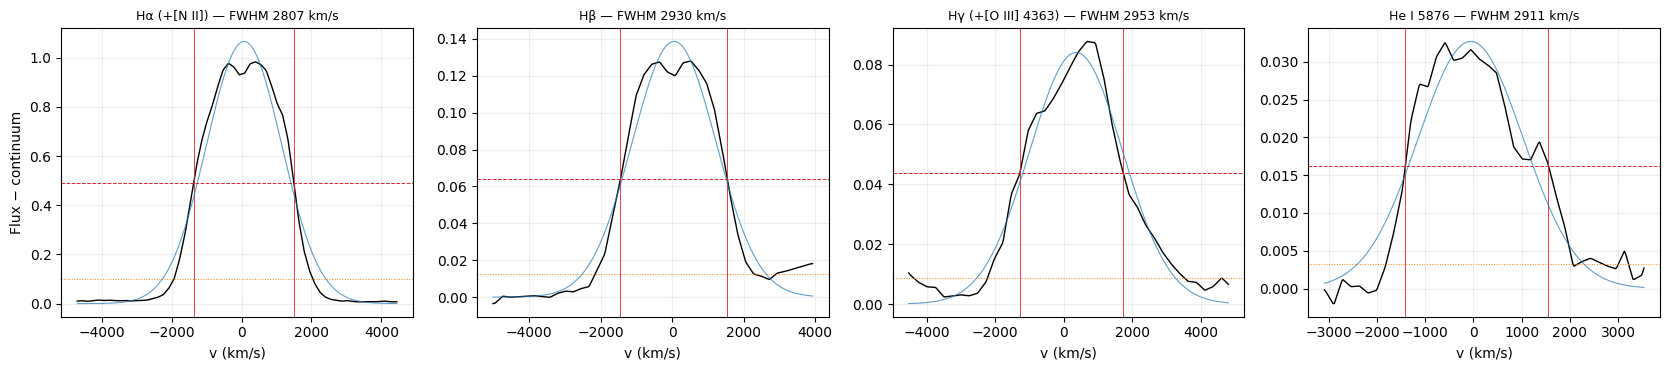

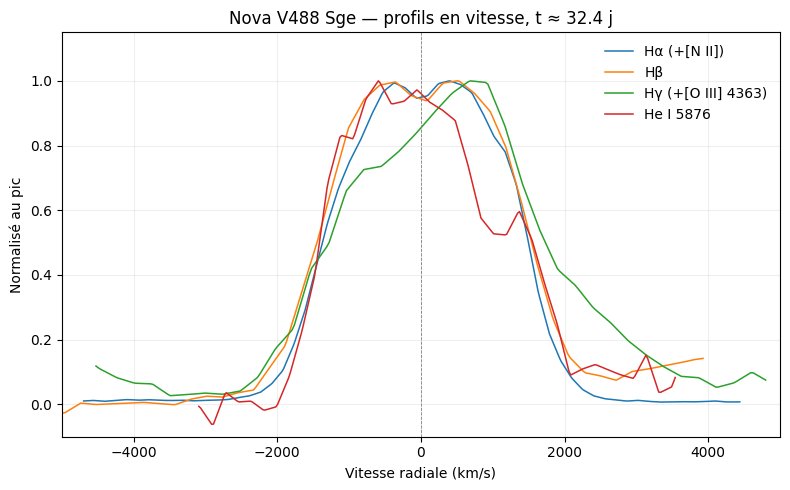

In [ ]:
# --- Contrôle visuel des mesures ---
n = len(res)
fig, axs = plt.subplots(1, n, figsize=(4.2 * n, 3.8), squeeze=False)
for ax, r in zip(axs[0], res):
    v = (r['x'] - r['lam0']) / r['lam0'] * C_KMS
    ax.plot(v, r['y'], 'k', lw=1)
    ax.axhline(0.5 * r['peak'], color='tab:red', lw=0.7, ls='--')
    ax.axhline(0.1 * r['peak'], color='tab:orange', lw=0.7, ls=':')
    for xx in (r['xl'], r['xr']):
        if np.isfinite(xx): ax.axvline((xx - r['lam0']) / r['lam0'] * C_KMS, color='tab:red', lw=0.6)
    if r['pfit'] is not None:
        ax.plot(v, gauss(r['x'], *r['pfit']), color='tab:blue', lw=0.8, alpha=0.7)
    ax.set_title(f"{r['label']} — FWHM {r['fwhm_dec']:.0f} km/s", fontsize=9)
    ax.set_xlabel('v (km/s)'); ax.grid(alpha=0.2)
axs[0][0].set_ylabel('Flux − continuum')
plt.tight_layout(); plt.show()

# --- Superposition des profils en vitesse (normalisés au pic) ---
fig, ax = plt.subplots(figsize=(8, 5))
for r in res:
    v = (r['x'] - r['lam0']) / r['lam0'] * C_KMS
    ax.plot(v, r['y'] / r['peak'], lw=1.1, label=r['label'])
ax.axvline(0, color='gray', lw=0.6, ls='--')
ax.set_xlim(-5000, 5000); ax.set_ylim(-0.1, 1.15)
ax.set_xlabel('Vitesse radiale (km/s)'); ax.set_ylabel('Normalisé au pic')
ax.set_title(f'{OBJECT} — profils en vitesse, t ≈ {AGE:.1f} j')
ax.legend(frameon=False); ax.grid(alpha=0.2)
plt.tight_layout(); plt.show()

## 6. Diagnostic de phase (flux relatifs à Hβ)

Flux intégrés au-dessus du pseudo-continuum dans des fenêtres fixes (à ajuster), rapportés à Hβ = 100, avec S/N. Puis une classification **indicative** inspirée du système de Tololo (Williams et al. 1991) :

- **C** (coronale) si [Fe X] 6375 > [Fe VII] 6087 et détectée ;
- sinon on regarde la raie non-Balmer la plus forte : permise → **P**, aurorale ([N II] 5755) → **A**, nébulaire ([O III] 5007, [Ne III]…) → **N**.

⚠ À R ≈ 500 avec des raies de ~2000 km/s, beaucoup de fenêtres sont blendées : [Fe X] 6375 avec [O I] 6364, He II 4686 avec N III 4640, Hγ avec [O III] 4363, [O III] 4959/5007 avec l'aile rouge de Hβ. Le résultat est une orientation, pas une classification publiable.

In [ ]:
# (label, λ0, (λmin, λmax), type)  type ∈ balmer / perm / aur / neb / cor
FLUX_LINES = [
    ("Hβ",             4861.3, (4800, 4915), 'balmer'),
    ("Hα+[N II]",      6562.8, (6470, 6655), 'balmer'),
    ("N III 4640",     4640.0, (4605, 4665), 'perm'),
    ("He II 4686",     4685.7, (4665, 4720), 'perm'),
    ("He I 5876",      5875.6, (5830, 5925), 'perm'),
    ("He I 6678",      6678.2, (6655, 6705), 'perm'),
    ("He I 7065",      7065.2, (7035, 7100), 'perm'),
    ("Fe II 5169",     5169.0, (5150, 5190), 'perm'),
    ("N II 5679",      5679.6, (5650, 5715), 'perm'),
    ("O I 7773",       7773.4, (7745, 7805), 'perm'),
    ("[N II] 5755",    5754.6, (5720, 5795), 'aur'),
    ("[O III] 4959",   4958.9, (4930, 4982), 'neb'),
    ("[O III] 5007",   5006.8, (4982, 5045), 'neb'),
    ("[Ne III] 3869",  3868.8, (3845, 3895), 'neb'),
    ("[O I] 6300",     6300.3, (6275, 6330), 'neb'),
    ("[Ar III] 7136",  7135.8, (7115, 7160), 'neb'),
    ("[Fe VII] 6087",  6086.9, (6060, 6115), 'cor'),
    ("[Fe X] 6375",    6374.5, (6362, 6395), 'cor'),
]

def line_flux(win):
    m = (wl >= win[0]) & (wl <= win[1])
    if m.sum() < 3:
        return np.nan, np.nan
    dl = np.median(np.diff(wl))
    return np.sum((fn[m] - cont[m])) * dl, SIGMA * np.sqrt(m.sum()) * dl

tab = []
for name, lam, win, typ in FLUX_LINES:
    if wl[0] <= win[0] and wl[-1] >= win[1]:
        F, eF = line_flux(win)
        tab.append((name, lam, typ, F, eF))
FHB = next(F for n_, _, _, F, _ in tab if n_ == 'Hβ')

print(f"{'raie':16s} {'type':7s} {'F/F(Hβ)×100':>12s} {'S/N':>6s}")
for name, lam, typ, F, eF in tab:
    print(f"{name:16s} {typ:7s} {100*F/FHB:12.1f} {F/eF:6.1f}")

# --- Classification indicative ---
det = {n_: F for n_, _, _, F, eF in tab if F / eF > 3}
typ_of = {n_: t for n_, _, t, _, _ in tab}
# [Fe X] 6375 est blendée avec [O I] 6364 (≈ 1/3 de [O I] 6300) : on n'accepte la phase
# coronale que si le flux dans la fenêtre 6375 dépasse [O I] 6300 ET [Fe VII] 6087.
fex, fevii, oi = det.get('[Fe X] 6375', 0), det.get('[Fe VII] 6087', 0), det.get('[O I] 6300', 0)
coronal = fex > 0 and fex > oi and fex > fevii
nb = {k: v for k, v in det.items() if typ_of[k] not in ('balmer', 'cor')}
ranked = sorted(nb, key=nb.get, reverse=True)
print("\nRaies non-Balmer les plus fortes (Hβ = 100) : " +
      ", ".join(f"{k} ({100*nb[k]/FHB:.0f})" for k in ranked[:4]))
if coronal:
    phase = 'C (coronale)'
elif ranked:
    top = ranked[0]
    phase = {'perm': 'P (permise)', 'aur': 'A (aurorale)', 'neb': 'N (nébulaire)'}[typ_of[top]] \
            + f' — raie non-Balmer la plus forte : {top}'
    if len(ranked) > 1 and nb[ranked[1]] > 0.8 * nb[top] and typ_of[ranked[1]] != typ_of[top]:
        phase += f'  (⚠ {ranked[1]} presque aussi forte : transition probable)'
else:
    phase = 'indéterminée (aucune raie non-Balmer à S/N > 3)'
if fex > 0 and not coronal:
    print("[Fe X] 6375 : excès compatible avec [O I] 6364 seul → pas de phase coronale établie.")
print(f"Phase indicative (type Tololo) : {phase}")

if 'Hα+[N II]' in det:
    print(f"Hα+[N II] / Hβ = {det['Hα+[N II]']/FHB:.2f}  "
          "(décrément de Balmer : significatif seulement si le spectre est corrigé de la réponse instrumentale)")

raie             type     F/F(Hβ)×100    S/N
Hβ               balmer         100.0  118.1
Hα+[N II]        balmer         946.2  881.7
N III 4640       perm            60.1   98.0
He II 4686       perm            24.2   41.2
He I 5876        perm            26.1   33.9
He I 6678        perm             6.8   12.2
He I 7065        perm            22.1   34.6
Fe II 5169       perm             4.7    9.4
N II 5679        perm            13.5   21.2
[N II] 5755      aur             10.2   14.9
[O III] 4959     neb             18.1   31.7
[O III] 5007     neb             52.2   83.1
[Ne III] 3869    neb             28.4   50.8
[O I] 6300       neb              6.6   11.3
[Ar III] 7136    neb              2.5    4.8
[Fe VII] 6087    cor             -2.3   -3.9
[Fe X] 6375      cor              5.1   11.1

Raies non-Balmer les plus fortes (Hβ = 100) : N III 4640 (60), [O III] 5007 (52), [Ne III] 3869 (28), He I 5876 (26)
[Fe X] 6375 : excès compatible avec [O I] 6364 seul → pas de phase coron

## 7. Ce qui est pertinent à ce stade (≈ 1 mois après l'éruption)

- **Vitesses** : FWHM et HWZI de Hα/Hβ, à comparer aux ~1500 km/s du P Cygni du jour de la découverte. Des profils plats ou à cornes indiquent une coquille optiquement mince ; une asymétrie persistante suggère une éjection non sphérique.
- **Transition de phase** : l'apparition et la croissance de **[O III] 4959/5007** et **[N II] 5755** marquent l'entrée en phase aurorale → nébulaire. Le rapport [N II] 5755 / [O III] 5007 est élevé tant que la densité reste forte (5755 est une raie aurorale).
- **He II 4686** : sa montée par rapport à Hβ trace le durcissement du rayonnement de la naine blanche — c'est le pendant optique de l'allumage de la source super-molle (SSS) en X.
- **Raies coronales** [Fe VII] 6087, [Fe X] 6375 : attendues surtout chez les novae rapides ; leur détection est intéressante (blend avec [O I] 6364 à surveiller).
- **Suivi temporel** : un seul spectre donne une photo ; la vraie valeur vient de la série (même réglage, mêmes fenêtres) — le code est prêt pour être bouclé sur plusieurs FITS, comme pour 2026rdg.

## 8. Suivi multi-époques avec la base ARAS (F. Teyssier)

Téléchargement de l'archive complète des spectres de V488 Sge de l'ARAS Spectral Database, puis application **des mêmes mesures** (pseudo-continuum, FWHM, HW10, flux relatifs à Hβ, phase) à chaque spectre.

Choix de sélection :
- **largeurs** : tous les spectres qui couvrent la raie (y compris échelles R ≈ 9000 et Star'Ex Hα R ≈ 14 000). Grâce à la déconvolution instrumentale, basse et haute résolution sont comparables ;
- **rapports de flux** : seulement les spectres basse résolution (R < 2000) qui couvrent 4250–6750 Å. On écarte les échelles (raccord des ordres) et les nuits du 25–26 août (SED incohérentes signalées sur la page ARAS) ;
- **exclu** : `asdb_novasge2026_20260821_311.fit`, daté du 21 août, soit 4 jours avant la découverte. La date du header est très probablement erronée.

⚠ Aux premiers jours, les profils P Cygni font que la FWHM mesurée est celle de la composante en émission seule, et que les flux intégrés sont diminués par l'absorption.

In [ ]:
import os, zipfile, urllib.request, glob, warnings
import pandas as pd

ARAS_URL = 'https://raw.githubusercontent.com/aras-database/database/master/archives/novasge2026.zip'
ARAS_DIR = 'aras_novasge2026'
EXCLUDE  = {'asdb_novasge2026_20260821_311.fit'}   # date suspecte (avant la découverte)
SED_BAD  = ('2026-08-25', '2026-08-26')            # SED incohérentes (note ARAS)
ME       = 'JPN'                                   # mot-clé OBSERVER à mettre en évidence

if not os.path.isdir(ARAS_DIR):
    print('Téléchargement de l\'archive ARAS…')
    urllib.request.urlretrieve(ARAS_URL, 'novasge2026.zip')
    with zipfile.ZipFile('novasge2026.zip') as z:
        z.extractall(ARAS_DIR)

rows = []
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    for f in sorted(glob.glob(os.path.join(ARAS_DIR, '**', '*.fit*'), recursive=True)):
        h = fits.getheader(f)
        n, crpix = h['NAXIS1'], h.get('CRPIX1', 1)
        w0 = h['CRVAL1'] + (1 - crpix) * h['CDELT1']
        jd = h.get('JD-MID') or h.get('JD-OBS') or Time(h['DATE-OBS']).jd
        rows.append(dict(file=f, name=os.path.basename(f), date=str(h.get('DATE-OBS', ''))[:16],
                         jd=float(jd), t=float(jd) - t0.jd, obs=str(h.get('OBSERVER', '?')).strip(),
                         R=float(h.get('SPE_RPOW') or h.get('BSS_ITRP') or np.nan),
                         wmin=w0, wmax=w0 + (n - 1) * h['CDELT1'],
                         inst=str(h.get('BSS_INST', ''))))

db = pd.DataFrame(rows).sort_values('jd').reset_index(drop=True)
# R absent du header : valeurs de la page ARAS, sinon médiane de l'observateur, sinon 1000
R_OVERRIDE = {'asdb_novasge2026_20260827_894.fit': 560, 'asdb_novasge2026_20260911_881.fit': 764,
              'asdb_novasge2026_20260919_881.fit': 766, 'asdb_novasge2026_20260904_862.fit': 1102}
for k, v in R_OVERRIDE.items():
    db.loc[db['name'] == k, 'R'] = v
db['R'] = db['R'].where(db['R'] > 0)
db['R'] = db['R'].fillna(db.groupby('obs')['R'].transform('median')).fillna(1000)
_dup = db.assign(_k=db['jd'].round(4)).duplicated(subset=['obs', '_k'])   # doublons (même fichier déposé 2×)
db = db[~_dup].reset_index(drop=True)
db['excluded'] = db['name'].isin(EXCLUDE)
db['sed_bad']  = db['date'].str[:10].isin(SED_BAD)
db['lowres']   = db['R'] < 2000
db['full']     = (db['wmin'] <= 4250) & (db['wmax'] >= 6750)
db['me']       = db['obs'].str.upper().str.startswith(ME)

print(f"{len(db)} spectres, {db.excluded.sum()} exclu(s), de J{db.t[~db.excluded].min():+.1f} à J{db.t.max():+.1f}")
print(f"Basse résolution couvrant 4250–6750 Å : {(db.lowres & db.full & ~db.excluded).sum()}")
print(db.groupby('obs').agg(n=('name', 'size'), R=('R', 'median'),
                            premier=('t', 'min'), dernier=('t', 'max')).sort_values('n', ascending=False)
        .round(1).to_string())

Téléchargement de l'archive ARAS…
111 spectres, 1 exclu(s), de J+0.4 à J+32.5
Basse résolution couvrant 4250–6750 Å : 36
                    n        R  premier  dernier
obs                                             
David Cejudo       23   1158.0      0.6     27.5
Francois Teyssier  17   9000.0      0.5     25.4
VDesnoux           15  14483.0      3.4     21.3
Jim Edlin           9   9000.0     -4.1     23.8
SKEC                6   1000.0      0.7     12.7
V. Lecocq           5    600.0      9.4     31.4
Forrest Sims        5   9000.0      7.7     31.7
J. Michelet         5   1102.0      4.5     13.4
TBohlsen            4   1833.0      4.1     29.1
Eric Girardin       3    600.0      9.4     11.4
EBE                 2    511.0      7.4     17.5
SARO                2    765.0     17.4     25.4
gbertrand           2    650.0      9.4     20.4
LFranco             2    539.0      9.4     12.4
Leadbeater          2    555.5      0.4     17.4
CBuil               1  14621.0      0.6      0

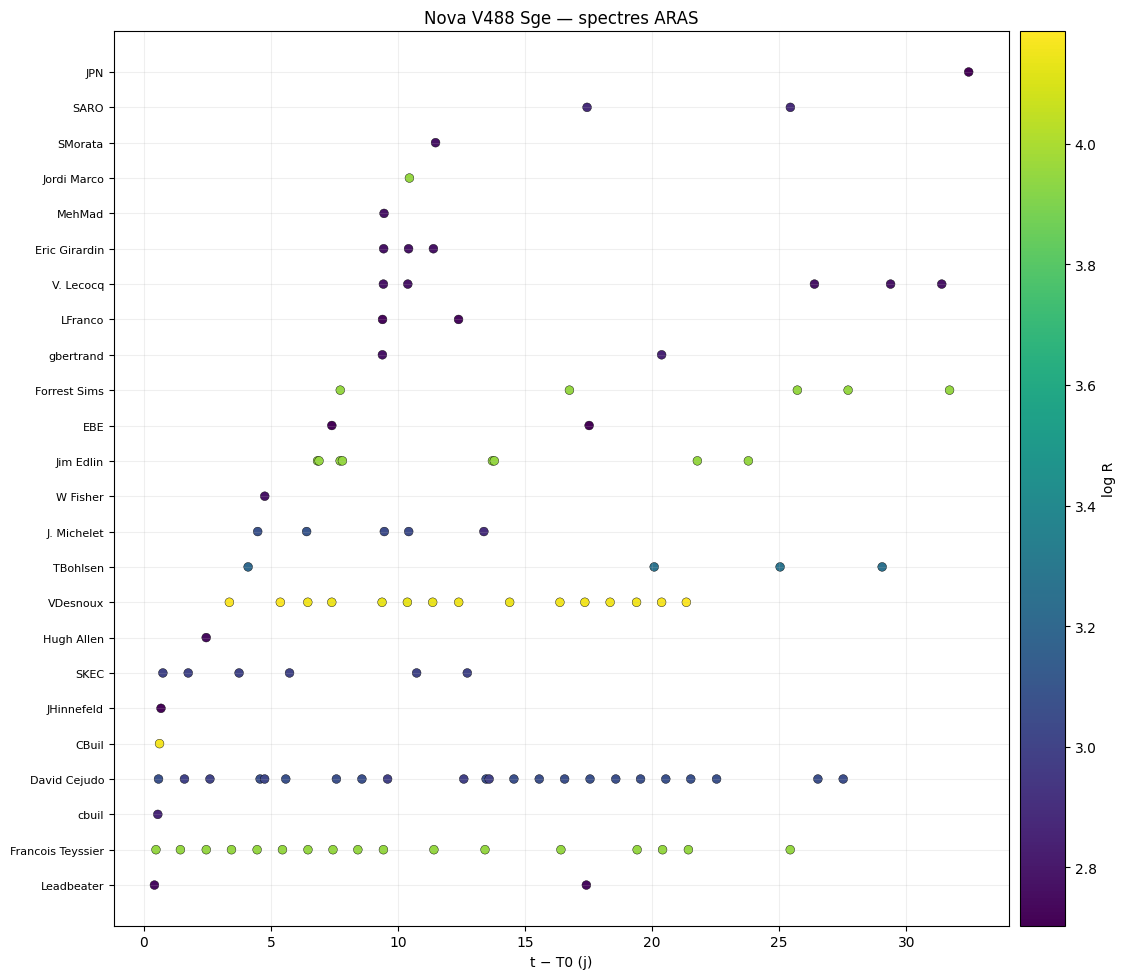

In [ ]:
# --- Chronologie des observations ---
d = db[~db.excluded]
obs_order = d.groupby('obs')['t'].min().sort_values().index.tolist()
fig, ax = plt.subplots(figsize=(12, 0.35 * len(obs_order) + 1.5))
sc = ax.scatter(d.t, [obs_order.index(o) for o in d.obs], c=np.log10(d.R), cmap='viridis',
                s=40, edgecolor='k', lw=0.3)
ax.set_yticks(range(len(obs_order))); ax.set_yticklabels(obs_order, fontsize=8)
ax.set_xlabel('t − T0 (j)'); ax.grid(alpha=0.2)
cb = plt.colorbar(sc, ax=ax, pad=0.01); cb.set_label('log R')
ax.set_title(f'{OBJECT} — spectres ARAS')
plt.tight_layout(); plt.show()

In [ ]:
# --- Analyse de chaque spectre avec les mêmes fonctions que plus haut ---
def build_continuum_safe(w, f, pts=CONT_POINTS, hw=HW):
    xs, ys = [], []
    for p in pts:
        mm = (w >= p - hw) & (w <= p + hw)
        if mm.sum() >= 3 and p - hw >= w[0] and p + hw <= w[-1]:
            xs.append(p); ys.append(np.median(f[mm]))
    if len(xs) < 2:                       # spectre étroit (ex. Hα seul) : ancrage aux bords
        e = 0.03 * (w[-1] - w[0])
        for a, b in [(w[0], w[0] + e), (w[-1] - e, w[-1])]:
            mm = (w >= a) & (w <= b)
            xs.append(0.5 * (a + b)); ys.append(np.median(f[mm]))
        o = np.argsort(xs); xs, ys = list(np.array(xs)[o]), list(np.array(ys)[o])
    xs, ys = np.array(xs), np.array(ys)
    c = PchipInterpolator(xs, ys, extrapolate=False)(w)
    c[w < xs[0]] = ys[0]; c[w > xs[-1]] = ys[-1]
    return c

def analyze_file(path, R):
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        w, fl, _ = load_spectrum(path)
    g = np.isfinite(fl); w, fl = w[g], fl[g]
    mha = (w > 6500) & (w < 6630)
    if mha.sum() < 5:
        return None
    f = fl / np.nanmax(fl[mha])
    c = build_continuum_safe(w, f)
    dp = np.median(np.diff(w))
    nbin = max(1, int(round(6000 / R / 2 / dp)))
    nb = len(f) // nbin
    sig = der_snr_noise(f[:nb * nbin].reshape(nb, nbin).mean(axis=1)) * np.sqrt(nbin)
    widths = {lab: measure_line(lab, lam0, win, wl=w, f=f, c=c, R=R)
              for lab, lam0, win in WIDTH_LINES if w[0] <= win[0] and w[-1] >= win[1]}
    fluxes = {}
    for name, lam, win, typ in FLUX_LINES:
        if w[0] <= win[0] and w[-1] >= win[1]:
            mm = (w >= win[0]) & (w <= win[1])
            fluxes[name] = (np.sum((f[mm] - c[mm]) * np.gradient(w[mm])), sig * np.sqrt(mm.sum()) * dp)
    return dict(w=w, f=f, c=c, widths=widths, fluxes=fluxes)

TYP = {n_: t_ for n_, _, _, t_ in FLUX_LINES}
def classify(fl):
    if 'Hβ' not in fl:
        return ''
    det = {k: F for k, (F, e) in fl.items() if e > 0 and F / e > 3}
    fhb = fl['Hβ'][0]
    fex, fevii, oi = det.get('[Fe X] 6375', 0), det.get('[Fe VII] 6087', 0), det.get('[O I] 6300', 0)
    feii = det.get('Fe II 5169', 0)
    # la fenêtre 6375 contient aussi [O I] 6364 et, en phase Fe II, Fe II 6369/6384 :
    # critère volontairement strict pour la phase coronale
    if fex > max(oi, fevii) and fex > 0.10 * fhb and feii < 0.10 * fhb:
        return 'C'
    if feii > 0.10 * fhb:          # phase Fe II : Fe II 5018 contamine la fenêtre [O III] 5007
        return 'P'
    nb = {k: v for k, v in det.items() if TYP[k] not in ('balmer', 'cor')}
    if not nb:
        return '?'
    return {'perm': 'P', 'aur': 'A', 'neb': 'N'}[TYP[max(nb, key=nb.get)]]

cache, out = {}, []
for _, s in db[~db.excluded].iterrows():
    a = analyze_file(s.file, s.R)
    if a is None:
        continue
    cache[s['name']] = a
    row = dict(name=s['name'], t=s.t, obs=s.obs, R=s.R, lowres=s.lowres, full=s.full,
               sed_bad=s.sed_bad, me=s.me)
    for lab, r in a['widths'].items():
        key = lab.split()[0]
        ok = np.isfinite(r['fwhm_dec']) and r['fwhm_dec'] > 400 and abs(r['v_cen']) < 1500
        row[f'FWHM_{key}'] = r['fwhm_dec'] if ok else np.nan      # filtre : pic parasite / raie ratée
        row[f'HW10b_{key}'] = r['hw10b'] if ok else np.nan
        row[f'HW10r_{key}'] = r['hw10r'] if ok else np.nan
    fl = a['fluxes']
    if 'Hβ' in fl and fl['Hβ'][0] > 0:
        for k, (F, e) in fl.items():
            row[f'r_{k}'] = F / fl['Hβ'][0]
        # phase seulement si N III 4640 → Ne III 3869 … 6750 sont couverts (sinon biais vers N)
        row['phase'] = classify(fl) if s.full else ''
    out.append(row)

res_db = pd.DataFrame(out).sort_values('t').reset_index(drop=True)
res_db.to_csv('v488sge_aras_mesures.csv', index=False)
cols = ['t', 'obs', 'R', 'FWHM_Hα', 'FWHM_Hβ', 'HW10b_Hα', 'phase']
print(res_db[[c for c in cols if c in res_db]].round(1).to_string(index=False))
print('\n→ tableau complet : v488sge_aras_mesures.csv')

   t               obs       R  FWHM_Hα  FWHM_Hβ  HW10b_Hα phase
 0.4        Leadbeater   560.0      NaN      NaN       NaN     P
 0.5 Francois Teyssier  9000.0      NaN    999.2       NaN   NaN
 0.5             cbuil   728.0      NaN    882.5       NaN   NaN
 0.6      David Cejudo  1185.0   1209.1   1036.9     878.5   NaN
 0.6             CBuil 14621.0      NaN      NaN       NaN   NaN
 0.7        JHinnefeld   522.0      NaN    841.4       NaN   NaN
 0.7              SKEC  1000.0   1037.3   1101.1     852.3   NaN
 1.4 Francois Teyssier  9000.0   1666.3   2363.2    1385.5     P
 1.6      David Cejudo   994.0   2326.0   2591.4    1987.9     P
 1.7              SKEC  1000.0   3167.4   2734.3    3635.2     P
 2.5        Hugh Allen   560.0   2892.9   3005.1    2762.0     P
 2.5 Francois Teyssier  9000.0   2786.1   2920.8    2096.0     P
 2.6      David Cejudo  1008.0   2913.4   2971.1    2703.3     P
 3.4          VDesnoux 15363.0   2922.3      NaN    2079.7   NaN
 3.4 Francois Teyssier  9

### 8.1 Évolution des vitesses
FWHM déconvoluée de Hα et Hβ, et demi-largeur à 10 % de Hα côté bleu et côté rouge (≈ vitesse maximale projetée). Les cercles sont la basse résolution, les carrés la haute résolution, l'étoile ton spectre.

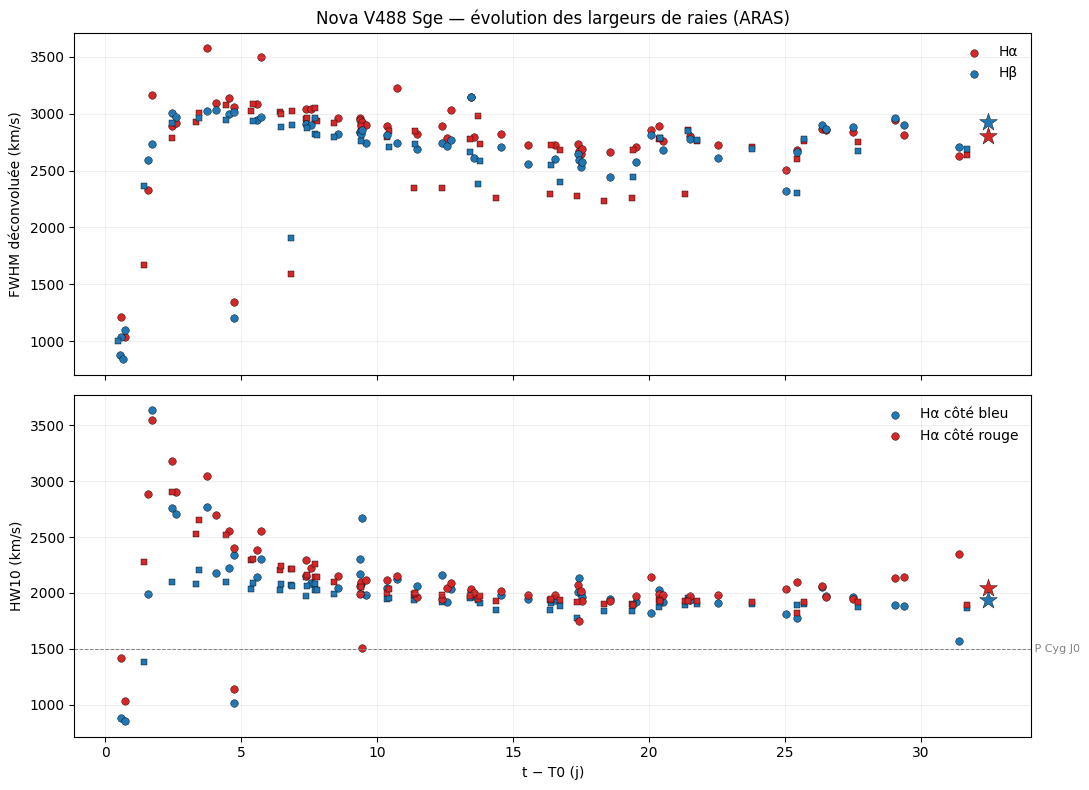

In [ ]:
def _style(df):
    hi = df.R >= 2000
    return [(df[~hi & ~df.me], 'o', 30), (df[hi & ~df.me], 's', 22), (df[df.me], '*', 180)]

fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
for key, col in [('Hα', 'tab:red'), ('Hβ', 'tab:blue')]:
    c = f'FWHM_{key}'
    if c not in res_db: continue
    for sub, mk, sz in _style(res_db.dropna(subset=[c])):
        a1.scatter(sub.t, sub[c], marker=mk, s=sz, color=col, edgecolor='k', lw=0.3,
                   label=key if mk == 'o' else None)
a1.set_ylabel('FWHM déconvoluée (km/s)'); a1.legend(frameon=False); a1.grid(alpha=0.2)
a1.set_title(f'{OBJECT} — évolution des largeurs de raies (ARAS)')

for c, col, lab in [('HW10b_Hα', 'tab:blue', 'Hα côté bleu'), ('HW10r_Hα', 'tab:red', 'Hα côté rouge')]:
    if c not in res_db: continue
    for sub, mk, sz in _style(res_db.dropna(subset=[c])):
        a2.scatter(sub.t, sub[c], marker=mk, s=sz, color=col, edgecolor='k', lw=0.3,
                   label=lab if mk == 'o' else None)
a2.axhline(1500, color='gray', ls='--', lw=0.7)
a2.text(a2.get_xlim()[1], 1500, ' P Cyg J0', va='center', fontsize=8, color='gray')
a2.set_ylabel('HW10 (km/s)'); a2.set_xlabel('t − T0 (j)')
a2.legend(frameon=False); a2.grid(alpha=0.2)
plt.tight_layout(); plt.show()

### 8.2 Évolution spectrale : flux relatifs à Hβ et phase
Basse résolution uniquement. L'échelle est log, et les lettres en haut indiquent la phase indicative de chaque spectre.

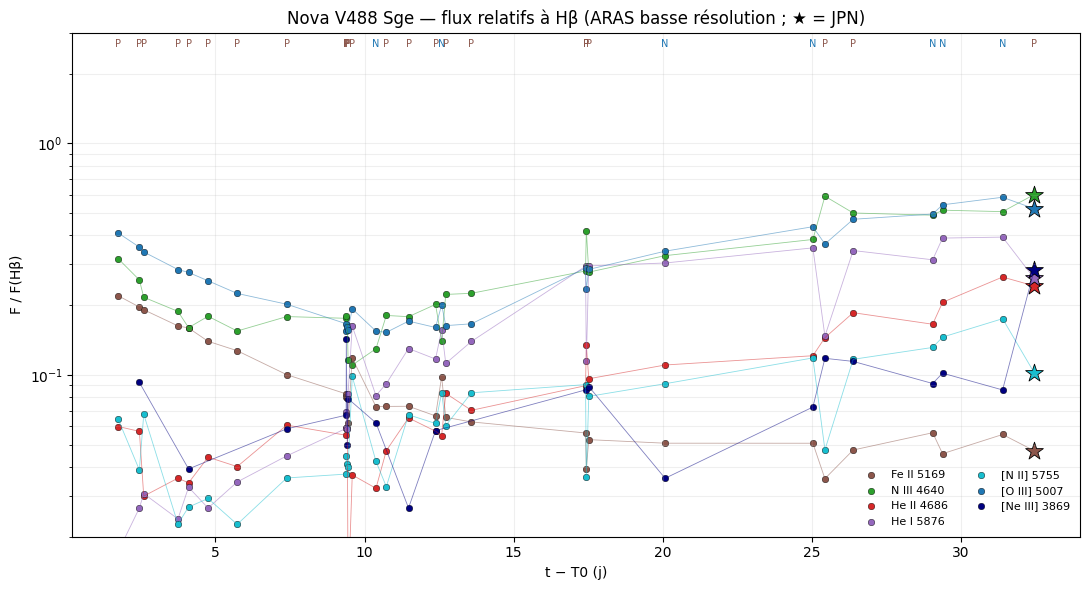

In [ ]:
RATIOS = [('Fe II 5169', 'tab:brown'), ('N III 4640', 'tab:green'), ('He II 4686', 'tab:red'),
          ('He I 5876', 'tab:purple'), ('[N II] 5755', 'tab:cyan'), ('[O III] 5007', 'tab:blue'),
          ('[Ne III] 3869', 'navy')]
sel = res_db[res_db.lowres & res_db.full & ~res_db.sed_bad]

fig, ax = plt.subplots(figsize=(11, 6))
for name, col in RATIOS:
    c = f'r_{name}'
    if c not in sel: continue
    s = sel[sel[c] > 0.01]
    ax.plot(s.t, s[c], '-', color=col, lw=0.6, alpha=0.5)
    ax.scatter(s.t, s[c], color=col, s=22, edgecolor='k', lw=0.3, label=name)
    m = s[s.me]
    ax.scatter(m.t, m[c], marker='*', s=180, color=col, edgecolor='k', lw=0.6)
ax.set_yscale('log'); ax.set_ylim(0.02, 3)
ax.set_xlabel('t − T0 (j)'); ax.set_ylabel('F / F(Hβ)')
ax.grid(alpha=0.2, which='both'); ax.legend(frameon=False, fontsize=8, ncol=2)
ax.set_title(f'{OBJECT} — flux relatifs à Hβ (ARAS basse résolution ; ★ = {ME})')
for _, r in sel.dropna(subset=['phase']).iterrows():
    ax.text(r.t, 2.6, r.phase, ha='center', fontsize=7,
            color={'P': 'tab:brown', 'A': 'tab:cyan', 'N': 'tab:blue', 'C': 'tab:orange'}.get(r.phase, 'gray'))
plt.tight_layout(); plt.show()

### 8.3 Séquence spectrale
Un spectre basse résolution par tranche de ~3 jours, normalisé à Hα, empilé en log.

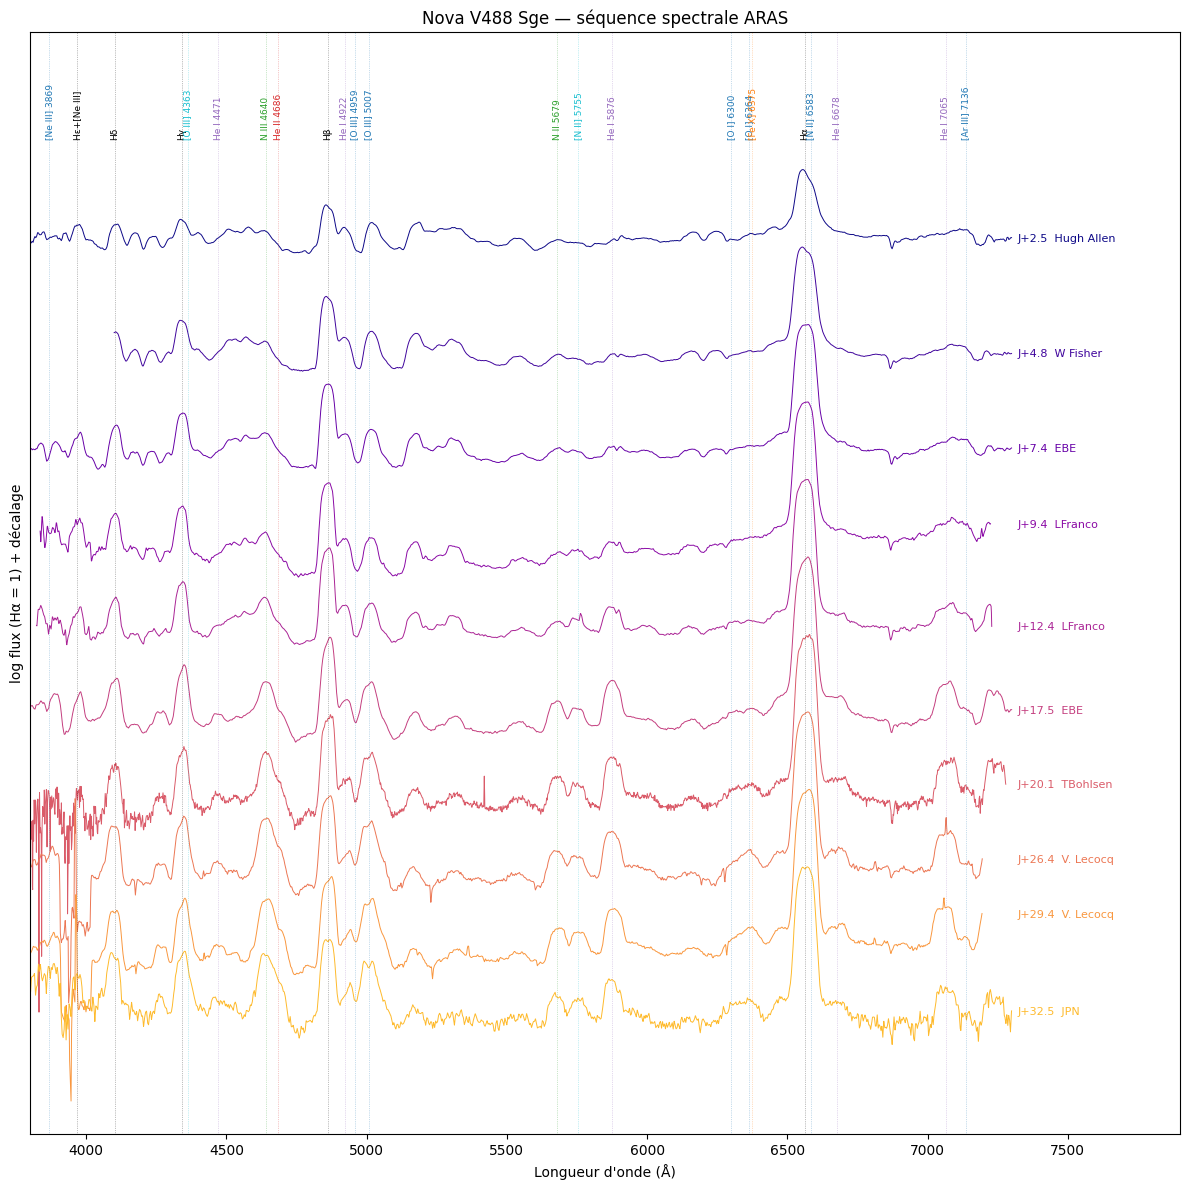

In [ ]:
STEP = 3.0
seq = sel.copy()
seq['bin'] = (seq.t // STEP).astype(int)
seq = seq.sort_values('R').groupby('bin').head(1).sort_values('t')   # 1 spectre par tranche
cmap = plt.get_cmap('plasma')
fig, ax = plt.subplots(figsize=(12, 1.0 * len(seq) + 2))
for k, (_, r) in enumerate(seq.iterrows()):
    a = cache[r['name']]
    m = (a['w'] > 3800) & (a['w'] < 7300) & (a['f'] > 0)
    y = np.log10(a['f'][m]) - 0.9 * k
    col = cmap(k / max(1, len(seq) - 1) * 0.85)
    ax.plot(a['w'][m], y, color=col, lw=0.7)
    ax.text(7320, y[-1], f"J{r.t:+.1f}  {r.obs}", fontsize=8, color=col, va='center')
for name, lam, cat, show in LINES:
    if show and 3800 < lam < 7300:
        ax.axvline(lam, color=CAT_COLORS.get(cat, 'gray'), ls=':', lw=0.5, alpha=0.5)
        ax.text(lam, 0.35, name, rotation=90, fontsize=6.5, ha='center', va='bottom',
                color=CAT_COLORS.get(cat, 'gray'))
ax.set_xlim(3800, 7900); ax.set_ylim(-0.9 * len(seq) - 2.2, 1.6)
ax.set_yticks([]); ax.set_xlabel("Longueur d'onde (Å)")
ax.set_ylabel('log flux (Hα = 1) + décalage')
ax.set_title(f'{OBJECT} — séquence spectrale ARAS')
plt.tight_layout(); plt.show()

### 8.4 Profil de Hα en haute résolution
Spectres R ≥ 5000 couvrant Hα, en vitesse et normalisés au pic : on y suit la disparition du P Cygni et l'apparition des cornes. Le trait vertical à −1500 km/s repère la vitesse de l'absorption P Cygni à J0.

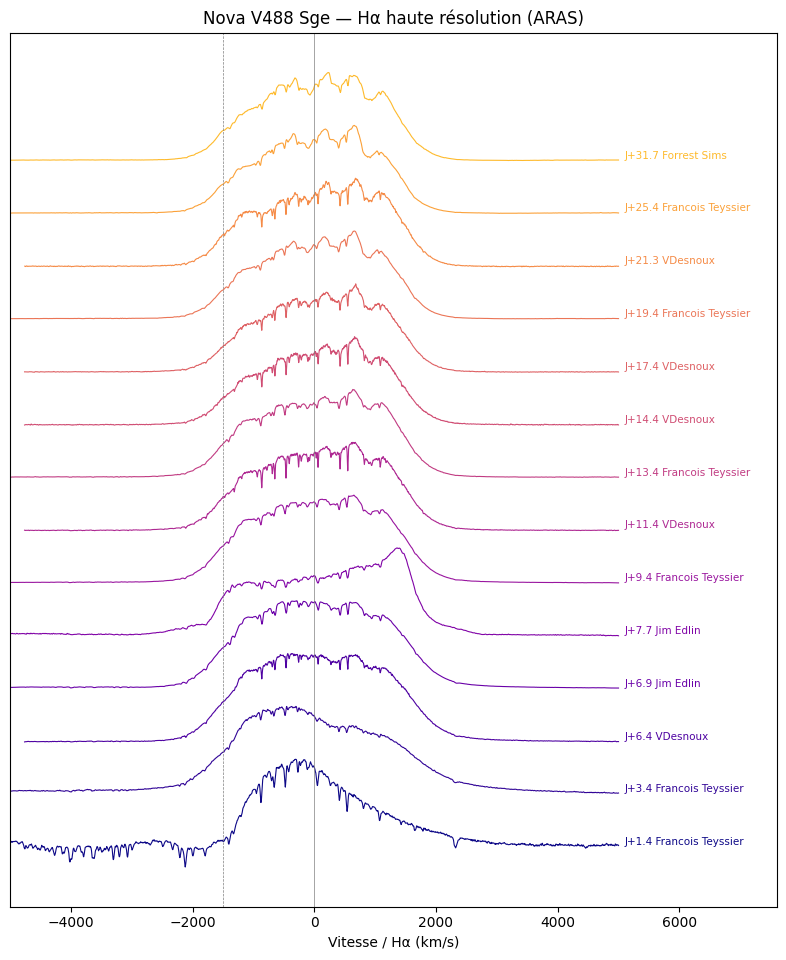

In [ ]:
NMAX = 14
hr = res_db[(res_db.R >= 5000) & res_db['FWHM_Hα'].notna()].copy()
if len(hr):
    idx = np.unique(np.linspace(0, len(hr) - 1, min(NMAX, len(hr))).round().astype(int))
    hr = hr.iloc[idx]
    fig, ax = plt.subplots(figsize=(8, 0.55 * len(hr) + 2))
    for k, (_, r) in enumerate(hr.iterrows()):
        a = cache[r['name']]
        v = (a['w'] - 6562.8) / 6562.8 * C_KMS
        m = np.abs(v) < 5000
        y = (a['f'][m] - a['c'][m]) / np.nanmax(a['f'][m] - a['c'][m])
        col = cmap(k / max(1, len(hr) - 1) * 0.85)
        ax.plot(v[m], y + 0.6 * k, color=col, lw=0.8)
        ax.text(5100, 0.6 * k, f"J{r.t:+.1f} {r.obs}", fontsize=7.5, color=col, va='bottom')
    ax.axvline(0, color='gray', lw=0.5); ax.axvline(-1500, color='gray', ls='--', lw=0.5)
    ax.set_xlim(-5000, 7600); ax.set_yticks([])
    ax.set_xlabel('Vitesse / Hα (km/s)')
    ax.set_title(f'{OBJECT} — Hα haute résolution (ARAS)')
    plt.tight_layout(); plt.show()

### 8.5 Recoupement de ton spectre avec les voisins temporels
Les spectres pris à ±1.5 j du tien sont ramenés à ta résolution (convolution gaussienne), puis comparés au tien, normalisés à Hα.

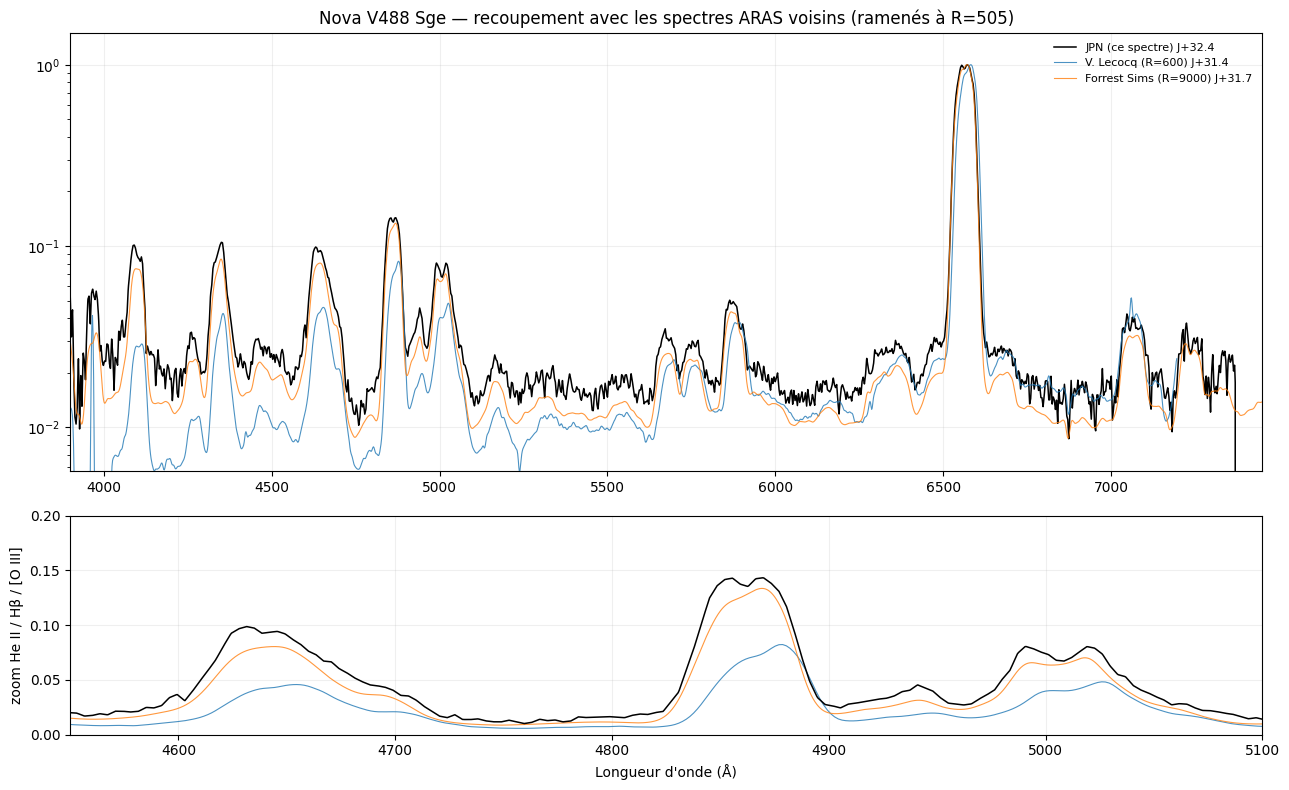

    t          obs      R  FWHM_Hα  FWHM_Hβ  r_N III 4640  r_He II 4686  r_[O III] 5007 phase
31.40    V. Lecocq  600.0  2628.01  2706.73          0.51          0.26            0.58     N
31.70 Forrest Sims 9000.0  2640.54  2688.69          0.58          0.22            0.53     P
32.46          JPN  505.0  2806.51  2930.05          0.60          0.24            0.52     P


In [ ]:
from scipy.ndimage import gaussian_filter1d

def degrade(w, f, R_from, R_to, lam_ref=5500.0):
    if not np.isfinite(R_from) or R_from <= R_to:
        return f
    dp = np.median(np.diff(w))
    s = np.sqrt((lam_ref / R_to) ** 2 - (lam_ref / R_from) ** 2) / 2.3548 / dp
    return gaussian_filter1d(f, s)

DT = 1.5
neigh = db[(~db.excluded) & (~db.me) & (np.abs(db.t - AGE) <= DT)]
fig, (a1, a2) = plt.subplots(2, 1, figsize=(13, 8), gridspec_kw={'height_ratios': [2, 1]})
a1.plot(wl, fn, color='k', lw=1.1, label=f'{ME} (ce spectre) J{AGE:+.1f}')
for _, s in neigh.iterrows():
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        w2, f2, _ = load_spectrum(s.file)
    g = np.isfinite(f2); w2, f2 = w2[g], f2[g]
    f2 = degrade(w2, f2, s.R, R_INST)
    mha = (w2 > 6500) & (w2 < 6630)
    if mha.sum() < 5: continue
    f2 = f2 / np.nanmax(f2[mha])
    lab = f"{s.obs} (R={s.R:.0f}) J{s.t:+.1f}"
    a1.plot(w2, f2, lw=0.8, alpha=0.8, label=lab)
    a2.plot(w2, f2, lw=0.8, alpha=0.8)
a2.plot(wl, fn, color='k', lw=1.1)
a1.set_yscale('log'); a1.set_ylim(np.percentile(fn[fn > 0], 1) * 0.5, 1.5)
a1.set_xlim(XLIM); a2.set_xlim(4550, 5100); a2.set_ylim(0, 0.2)
a1.legend(frameon=False, fontsize=8); a1.grid(alpha=0.2); a2.grid(alpha=0.2)
a1.set_title(f'{OBJECT} — recoupement avec les spectres ARAS voisins (ramenés à R={R_INST:.0f})')
a2.set_xlabel("Longueur d'onde (Å)"); a2.set_ylabel('zoom He II / Hβ / [O III]')
plt.tight_layout(); plt.show()

show_cols = ['t', 'obs', 'R', 'FWHM_Hα', 'FWHM_Hβ', 'r_N III 4640', 'r_He II 4686', 'r_[O III] 5007', 'phase']
near = res_db[np.abs(res_db.t - AGE) <= DT]
print(near[[c for c in show_cols if c in near]].round(2).to_string(index=False))

### 8.6 Lecture des courbes
- **Fe II 5169 / Hβ** qui s'effondre marque la fin de la phase P Cygni/Fe II. **N III 4640, He I** et **N II 5679** prennent le relais : c'est le caractère He/N.
- ⚠ Aux premiers jours, la fenêtre « [O III] 5007 » mesure en réalité **Fe II 5018** (multiplet 42), et la fenêtre « N III 4640 » un blend Fe II / N III. La décroissance initiale de ces courbes est donc celle de Fe II. Le vrai [O III] n'apparaît qu'ensuite, quand la courbe remonte.
- **[O III] 5007 / Hβ** croissant signale l'entrée en phase nébulaire. Le croisement avec N III 4640 date la bascule **P → N** dans le système de Tololo.
- **He II 4686 / Hβ** qui monte traduit le durcissement du rayonnement de la naine blanche, c'est-à-dire l'approche de la phase super-molle en X.
- **Largeurs** : une FWHM qui augmente avec le temps est classique (on voit progressivement toute l'éjecta, les composantes rapides apparaissant après le maximum). Un plateau des HW10 donne la vitesse terminale de l'éjecta.
- Les rapports de flux entre observateurs dépendent de la qualité de la correction de réponse. Il vaut mieux comparer des raies proches en λ (N III / He II / Hβ / [O III]) que Hα/Hβ.